# Where should the 1990 ambulances wait?
### p-median location of ambulance bases in the North Western Province, Sri Lanka

"1990 Suwa Seriya" is Sri Lanka's free pre-hospital ambulance service. Where ambulances wait
between calls decides how fast they reach patients. We choose **p ambulance bases** from a set
of candidate sites so that the **population-weighted average response time** to all 2,158
Grama Niladhari (GN) divisions of the North Western Province (Kurunegala + Puttalam) is as
small as possible.

**Methods compared**
* **Exact:** p-median Integer Linear Program, solved by CBC branch-and-bound (PuLP)
* **Bound:** LP relaxation of the ILP
* **Heuristic:** Greedy-add construction, improved by Simulated Annealing (swap moves)

**Data.** Census of Population and Housing 2012 (Department of Census and Statistics):
GN- and DS-division centroids and populations, republished at github.com/nuuuwan/gig-data.

### Contents

| § | Section |
|---|---|
| 0 | Setup and evaluation metrics |
| 1 | Data and travel-time model |
| 2 | Mathematical formulation (p-median ILP) |
| 3 | Exact method and LP lower bound |
| 4 | Worked example: exact solution for Puttalam |
| 5 | Experiment E1: realistic case |
| 6 | Heuristics: Greedy and Simulated Annealing |
| 7 | Worked example: heuristics vs the exact optimum |
| 8 | Experiment E2: scalability |
| 9 | Experiment E3: how many bases? |
| 10 | Discussion and conclusion |

### Team and contributions

| | Name | Student ID |
|---|---|---|
| **Member 1** | Anurangi PALA | MS26910154 |
| **Member 2** | Jayakumara MASC | MS26912134 |

**Member 1**: data preparation and travel-time model, p-median ILP formulation and
implementation, LP relaxation bound, experiment E1 (realistic case), report sections 2–4.
Code: `src/ambupos/data.py`, `src/ambupos/ilp.py`.

**Member 2**: greedy heuristic, Simulated Annealing design and tuning, experiments E2
(scalability) and E3 (number-of-bases trade-off), all figures, report sections 5–7.
Code: `src/ambupos/heuristics.py`, `plots.py`.

Shared: `src/ambupos/evaluate.py` (common scoring) and `experiments.py` (runs E1–E3, saves `results/`).

## 0. Setup and evaluation metrics

Every method returns only the list of **open bases**. The shared `evaluate()` function then
assigns each GN division to its nearest open base and computes the same metrics for every
method, so all answers are compared on exactly the same basis:

| Metric | Meaning |
|---|---|
| `objective` | total population-weighted minutes, the quantity the model minimises |
| `avg_time` | average response time per person (min); **lower is better** |
| `max_time` | response time of the worst-served GN division (min) |
| `cover_15`, `cover_30` | share of the population reached within 15 / 30 minutes |
| `runtime` | solver time in seconds |

In [1]:
import sys, json
sys.path.insert(0, "src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from ambupos import (make_instance, load_gnd, load_dsd, greedy, simulated_annealing,
                     solve_ilp, solve_lp_relaxation, evaluate)
from ambupos import data as D
pd.set_option("display.precision", 3)

## 1. Data and travel-time model

* **Demand points = GN divisions** (Grama Niladhari, the smallest administrative unit).
  Each has a centroid (lat/lon) and a 2012 census population. Population is the *weight*:
  a GN division with more people counts more in the objective.
* **Candidate bases = DS division centres** (Divisional Secretariat, 46 in the province).
  Each DS centre is a town that usually has a hospital or police station, so it is a
  realistic place to keep an ambulance.
* The province has two districts: **Kurunegala** (larger, inland) and **Puttalam** (coastal).
* For the scalability experiment (E2) a second candidate set is used: GN centroids sampled
  at random without replacement, with probability proportional to population, so that the
  number of candidate sites $|J|$ can be varied from 25 up to all 2,158.

`make_instance(p, district, sites)` builds one problem instance: it selects the demand rows
(one district or the whole province), selects the candidate sites, and precomputes the
weight vector $w$ and the travel-time matrix $t$ once, so every solver reads the same data.

GN divisions per district and their population statistics:

In [2]:
gnd, dsd = load_gnd(), load_dsd()
print(f"GN divisions: {len(gnd):,}   DS divisions: {len(dsd)}   population: {gnd.population.sum():,}")
gnd.groupby("district").population.agg(["count", "sum", "mean", "min", "max"])

GN divisions: 2,158   DS divisions: 46   population: 2,379,683


,count,sum,mean,min,max
district,,,,,
Kurunegala,1610,1617287,1004.526,161,4326
Puttalam,548,762396,1391.234,113,14017


In [3]:
gnd.head()

,id,name,district,dsd_id,lat,lon,population
0,LK-6103005,Jayanthipura,Kurunegala,LK-6103,8.179,80.113,819
1,LK-6103010,Bambare,Kurunegala,LK-6103,8.174,80.136,1094
2,LK-6103015,Sandagala Palatha,Kurunegala,LK-6103,8.162,80.110,1003
3,LK-6103020,Perakumpura,Kurunegala,LK-6103,8.160,80.136,1422
4,LK-6103025,Solepura,Kurunegala,LK-6103,8.155,80.153,1149


*Each row is one GN division: its name, district, centroid coordinates, and population.*

**Travel-time assumption.** No road network is available, so travel time is estimated from distance:

$$t_{ij} = \frac{\text{haversine\_km}(i, j) \times \text{CIRCUITY}}{\text{SPEED}} \times 60 \quad\text{minutes}$$

* *Haversine* = great-circle ("as the crow flies") distance between the two centroids,
  $d = 2R\arcsin\sqrt{\sin^2\frac{\Delta\phi}{2} + \cos\phi_1\cos\phi_2\sin^2\frac{\Delta\lambda}{2}}$ with $R = 6371$ km.
* *Circuity* = 1.4: road distance is taken as about 40% longer than the straight line,
  a typical detour factor for rural road networks.
* *Speed* = 40 km/h, an average ambulance speed on mixed rural/town roads.

The matrix is computed in one vectorised NumPy step (broadcasting demand × sites), giving
$t$ of shape $|I| \times |J|$, with one row per GN division, one column per candidate base.
All three methods use this same matrix, so differences in results come only from the method.

In [4]:
print("CIRCUITY =", D.CIRCUITY, "  SPEED_KMH =", D.SPEED_KMH)

CIRCUITY = 1.4   SPEED_KMH = 40.0


## 2. Mathematical formulation (p-median)

| Symbol | Meaning |
|---|---|
| $I$ | demand points (GN divisions), $J$ candidate base sites |
| $w_i$ | population of GN division $i$ |
| $t_{ij}$ | travel time (min) from site $j$ to GN division $i$ |
| $p$ | number of bases to open |
| $y_j\in\{0,1\}$ | 1 if a base is opened at site $j$ |
| $x_{ij}\in[0,1]$ | 1 if GN division $i$ is served from site $j$ |

$$\min \sum_{i\in I}\sum_{j\in J} w_i\, t_{ij}\, x_{ij}$$
subject to
$$\sum_{j} x_{ij}=1\;\;\forall i,\qquad x_{ij}\le y_j\;\;\forall i,j,\qquad \sum_j y_j = p,\qquad y_j\in\{0,1\}.$$

**In words**
* **Objective:** add up (people × minutes) over all GN divisions → minimise total person-minutes.
  Dividing by total population gives the **average response time per person**.
* $\sum_j x_{ij} = 1$: every GN division is served by exactly one base.
* $x_{ij} \le y_j$: a GN division can only be served by a base that is open.
  (This is the *disaggregated* form. The aggregated form $\sum_i x_{ij} \le |I|\,y_j$ has far
  fewer constraints but a much weaker LP relaxation, so we use one constraint per pair.)
* $\sum_j y_j = p$: exactly $p$ bases are opened (the budget).

**Why $x_{ij}$ can be continuous.** Once the $y_j$ are fixed, the best choice is to send each
GN division entirely to its nearest open base, which is an integral $x$. So only the $|J|$
location variables $y_j$ need to be binary; branch-and-bound only branches on those.

**Problem size.** There are $|J| + |I|\cdot|J|$ variables and $|I| + |I|\cdot|J| + 1$
constraints. With the 46 DS centres that is about 99,000 variables; with all 2,158 GN centres
as candidates it is about **4.7 million** variables and constraints, which is why the exact
method stops being practical on large cases (see E2).

## 3. Exact method and LP lower bound

**Integer Linear Programming (ILP).** The model above is built in PuLP (`build_model`) and
solved with the CBC solver, which uses LP-based branch-and-bound with cutting planes:
1. Solve the LP relaxation at the root node to get a lower bound.
2. If some $y_j$ is fractional, branch on it ($y_j = 0$ / $y_j = 1$) and solve each sub-problem.
3. Any integral solution found gives an upper bound; nodes whose LP bound is worse than the
   best integral solution are pruned.
4. Stop when the gap between the best bound and the best solution is closed (**proven optimum**)
   or when the time limit is reached (best solution so far, **not proven**).

Settings: single thread, 300 s CBC time limit. In the experiments the solve also runs in a
separate process that is killed after 600 s wall-clock, because CBC does not check its time
limit while still solving the root LP of a very large model. A result is marked
`optimal = True` only if CBC reports "Optimal" *and* it finished before the time limit.

**LP relaxation (lower bound).** The same model with $0 \le y_j \le 1$ instead of binary
(`solve_lp_relaxation`). Every feasible ILP solution is also feasible for the LP, so

$$z_{LP} \;\le\; z_{ILP}^* \;\le\; z_{\text{any heuristic}}.$$

The LP value therefore measures how far any solution could be from optimal:
$\text{gap} = (z - z_{LP}) / z_{LP}$. If $z_{LP} = z_{ILP}$ the relaxation is *tight* and the
ILP answer is certified optimal without much branching.

## 4. Worked example: exact solution for Puttalam (16 DS centres, p = 4)

A small instance that solves in seconds. The cell below builds the instance (Puttalam GN
divisions as demand, its 16 DS centres as candidates, open 4 bases), solves the ILP and the
LP relaxation, and reports the optimal bases together with the optimality gap.

In [5]:
inst = make_instance(p=4, district="Puttalam")
print(f"Instance {inst.name}: |I| = {inst.I} GN divisions, |J| = {inst.J} candidate sites, p = {inst.p}")
ilp = solve_ilp(inst, time_limit=60)
lp  = solve_lp_relaxation(inst)
e_ilp = evaluate(inst, ilp["open"])
print(f"ILP status: {ilp['status']}  ({ilp['n_vars']:,} variables, {ilp['runtime']:.2f} s)")
print(f"ILP average time : {e_ilp['avg_time']:.3f} min")
print(f"LP lower bound   : {lp['lp_bound'] / inst.w.sum():.3f} min")
print(f"Optimality gap   : {100 * (e_ilp['objective'] / lp['lp_bound'] - 1):.3f} %")
print("Optimal bases    :", ", ".join(inst.sites.name[ilp["open"]]))

Instance Puttalam_dsd_p4: |I| = 548 GN divisions, |J| = 16 candidate sites, p = 4


ILP status: Optimal  (8,784 variables, 0.85 s)
ILP average time : 21.457 min
LP lower bound   : 21.457 min
Optimality gap   : 0.000 %
Optimal bases    : Puttalam, Mahakumbukkadawala, Chilaw, Wennappuwa


The LP bound equals the ILP value, so the gap is zero and the four bases are a **proven optimum**.

## 5. Experiment E1: realistic case (candidate bases = DS-division centres)

**Goal:** measure how good the heuristics are against the true optimum, on instances where
the ILP can still be solved. Three instances: Puttalam (p = 4), Kurunegala (p = 7),
whole NWP (p = 10). SA is run with 10 random seeds; we report the **mean** (`avg_time`) and
the **best** seed (`best_avg`). The heuristics themselves are described in §6.

Results are pre-computed by `python experiments.py` (≈30–40 min in total, mostly ILP time)
and loaded here from `results/`; figures are drawn by `plots.py`.

In [6]:
e1 = pd.read_csv("results/e1_realistic.csv")
lpb = pd.read_csv("results/e1_lp_bounds.csv")
t1 = (e1.groupby(["instance", "method"])
        .agg(avg_time=("avg_time", "mean"), best_avg=("avg_time", "min"),
             max_time=("max_time", "mean"), cover_15=("cover_15", "mean"),
             cover_30=("cover_30", "mean"), runtime_s=("runtime", "mean"))
        .reset_index())
t1

,instance,method,avg_time,best_avg,max_time,cover_15,cover_30,runtime_s
0,Kurunegala_dsd_p7,Greedy,21.593,21.593,68.325,0.289,0.801,7.356e-04
1,Kurunegala_dsd_p7,ILP,21.030,21.030,50.510,0.291,0.812,8.213e+00
2,Kurunegala_dsd_p7,SA,21.043,21.030,51.236,0.291,0.811,2.874e-01
3,NWP_dsd_p10,Greedy,22.472,22.472,110.306,0.293,0.762,1.748e-03
4,NWP_dsd_p10,ILP,21.325,21.325,110.306,0.315,0.804,3.407e+01
5,NWP_dsd_p10,SA,21.333,21.325,110.306,0.315,0.803,3.672e-01
6,Puttalam_dsd_p4,Greedy,21.741,21.741,90.820,0.330,0.795,1.500e-04
7,Puttalam_dsd_p4,ILP,21.457,21.457,110.306,0.392,0.785,5.991e-01
8,Puttalam_dsd_p4,SA,21.457,21.457,110.306,0.392,0.785,2.545e-01


**Key observations:** ILP gives the lowest `avg_time` in every case. SA's `best_avg` matches the
ILP exactly, and its mean is within a few hundredths of a minute, while taking under half a
second. Greedy alone is noticeably worse (e.g. 22.47 vs 21.33 min for the whole province).

**LP relaxation lower bound.** Convert the LP bound (person-minutes) to an average time per
person by dividing by the population, so it can be compared with the table above.

In [7]:
W = {i: make_instance(p=1, district=d).w.sum() for i, d in
     [("Puttalam_dsd_p4", "Puttalam"), ("Kurunegala_dsd_p7", "Kurunegala"), ("NWP_dsd_p10", None)]}
lpb["lp_avg_time"] = [b / W[i] for i, b in zip(lpb.instance, lpb.lp_bound)]
lpb

,instance,lp_bound,lp_runtime,lp_avg_time
0,Puttalam_dsd_p4,1.636e+07,0.490,21.457
1,Kurunegala_dsd_p7,3.401e+07,7.552,21.030
2,NWP_dsd_p10,5.075e+07,20.336,21.325


**Key observations:** `lp_avg_time` equals the ILP `avg_time` for all three instances, so the LP
relaxation is *tight*, so the ILP answers are **proven optimal**, and the solver had very little
branching to do.

**Figure 1. Map of the optimal bases (whole province, p = 10, ILP solution).**
Each dot is a GN division (size ∝ population), coloured by the base that serves it.
Black × = candidate DS centres; gold ★ = the 10 chosen ambulance bases.

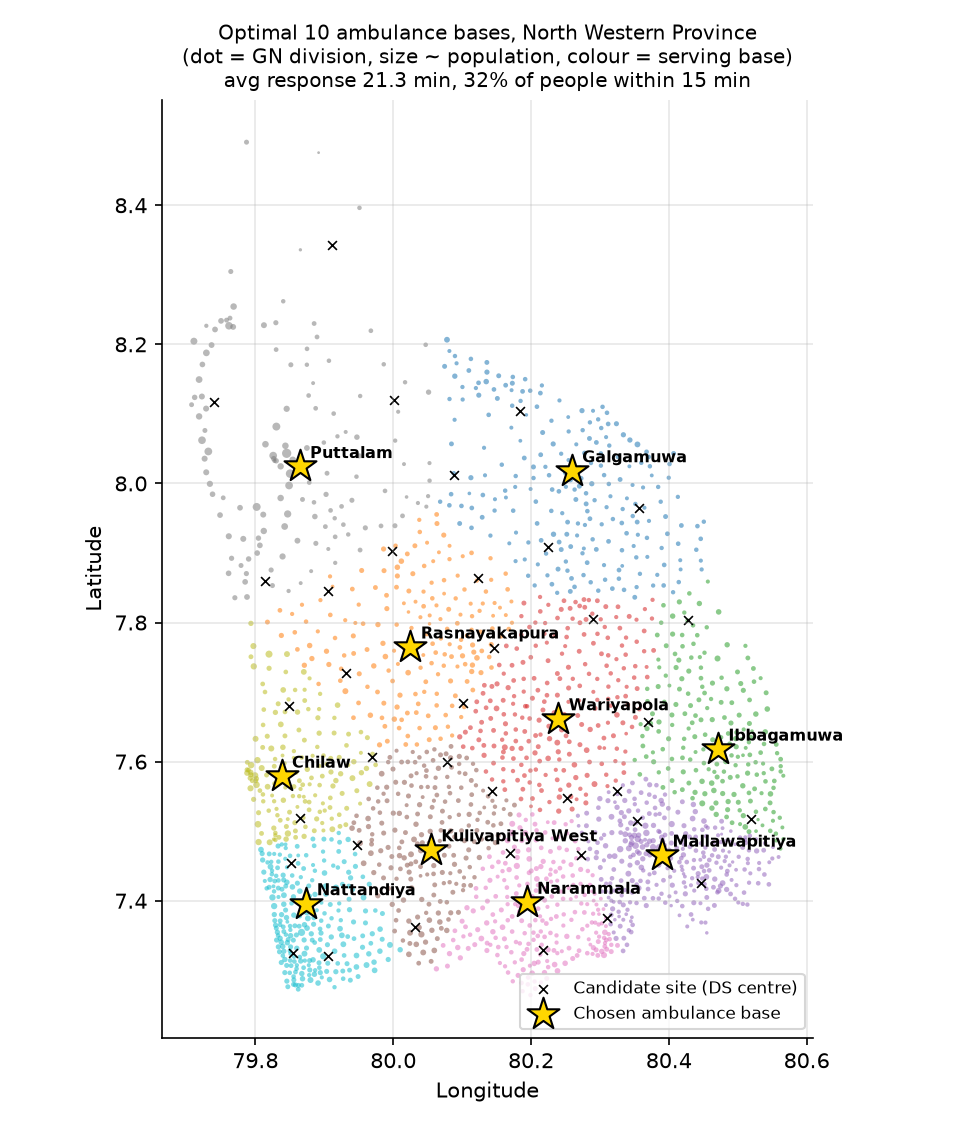

In [8]:
display(Image("figures/fig1_map_optimal_bases.png"))

### E1 summary
* The ILP found the proven optimum in all three cases.
* The LP relaxation gave the same value as the ILP (21.46, 21.03, 21.33 min), so the bound was tight and the ILP was easy to solve here.
* Greedy alone was about 1–5% worse than the optimum (worst: NWP, 22.47 vs 21.33 min).
* SA (started from greedy) reached the optimum in almost every run; only 1–2 of the 10 runs stopped slightly short.
* SA took less than half a second; the ILP took up to about 34 seconds.
* With 46 DS centres as candidates the exact method is practical. §8 (E2) examines what happens when the problem grows.

## 6. Heuristics: Greedy and Simulated Annealing

**Greedy (add) construction.** Start with no open bases and every GN's current time
$b_i = \infty$. In each of $p$ rounds, compute for every closed site $j$ the cost if it were added,
$\sum_i w_i \min(b_i, t_{ij})$ (one vectorised step for all $j$), open the site with the lowest
cost and update $b_i \leftarrow \min(b_i, t_{ij})$. Cost: $O(p\,|I|\,|J|)$. Fast, but an early
choice can never be undone, so it can end in a poor local solution.

**Simulated Annealing (SA) improvement.** Starts from the greedy solution.
* *Solution:* a set of $p$ open sites.
* *Move (swap):* pick a random open base $r$ to close and a random closed site $a$ to open.
* *Fast cost change:* for every GN we store the time to its nearest open base $d^{(1)}_i$, which
  base that is, and the time to its second-nearest $d^{(2)}_i$. After the swap, the new time is
  $$t'_i = \min\big(\,(d^{(2)}_i \text{ if } r \text{ was } i\text{'s nearest, else } d^{(1)}_i),\; t_{ia}\big),$$
  so $\Delta = \sum_i w_i t'_i - z$ is computed in $O(|I|)$ without re-assigning everything.
  The nearest/second-nearest arrays are only rebuilt when a move is accepted.
* *Acceptance (Metropolis rule):* accept if $\Delta \le 0$; otherwise accept with probability
  $e^{-\Delta/T}$. Early on this lets the search leave local optima.
* *Cooling schedule:* geometric, $T_k = T_0\,\alpha^k$, with $T_0 = 0.01\,z_0$ (1% of the
  starting cost), final temperature $10^{-5} z_0$, and $\alpha = (10^{-3})^{1/K}$ over
  $K = 20{,}000$ moves. Scaling $T$ to the cost makes the same settings work for every instance.
* *Output:* the best solution seen during the whole run (not the last one).
* *Reliability:* SA is randomised, so it is run with 10 seeds (5 in E3) and both the mean and
  the best result are reported.

## 7. Worked example: heuristics vs the exact optimum (Puttalam, p = 4)

Same instance as §4. Greedy builds a solution, SA improves it, and both are compared with
the ILP optimum found in §4.

In [9]:
g  = greedy(inst)
sa = simulated_annealing(inst, g["open"], seed=0)
rows = []
for name, res in [("Greedy", g), ("SA", sa), ("ILP (§4)", ilp)]:
    e = evaluate(inst, res["open"])
    rows.append({"method": name, "runtime_s": res["runtime"], **e,
                 "gap_to_opt_%": 100 * (e["objective"] / e_ilp["objective"] - 1),
                 "bases": ", ".join(inst.sites.name[res["open"]])})
print(f"SA: {sa['iters']:,} moves, acceptance rate {sa['accept_rate']:.1%}")
pd.DataFrame(rows)

SA: 20,000 moves, acceptance rate 0.7%


,method,runtime_s,feasible,objective,avg_time,max_time,cover_15,cover_30,gap_to_opt_%,bases
0,Greedy,2.020e-04,True,1.658e+07,21.741,90.820,0.330,0.795,1.327,"Kalpitiya, Puttalam, Arachchikattuwa, Nattandiya"
1,SA,3.356e-01,True,1.636e+07,21.457,110.306,0.392,0.785,0.000,"Puttalam, Mahakumbukkadawala, Chilaw, Wennappuwa"
2,ILP (§4),8.482e-01,True,1.636e+07,21.457,110.306,0.392,0.785,0.000,"Puttalam, Mahakumbukkadawala, Chilaw, Wennappuwa"


**Figure 5. SA convergence (whole province, p = 10, seed 0).** Best average time found so
far vs iteration. Grey dotted line = greedy start; blue dashed line = ILP optimum. SA starts at
the greedy solution, improves in steps and reaches the optimum line.

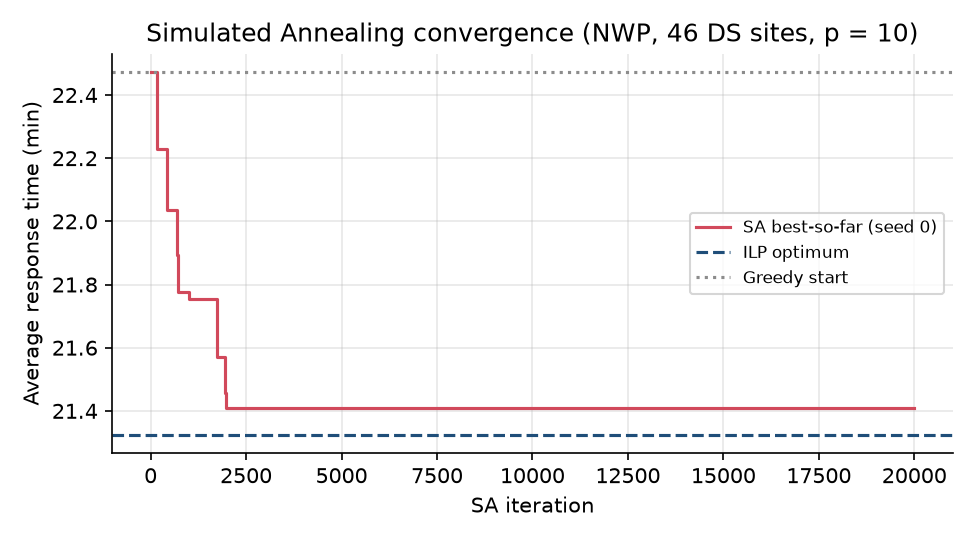

In [10]:
display(Image("figures/fig5_sa_convergence.png"))

## 8. Experiment E2: scalability (whole province, |J| = 25 … 2,158 candidate GN centres, p = 10)

**Goal:** see how each method copes as the number of candidate sites grows.
Candidate sites are GN centres sampled at random (more populated GNs more likely).
SA uses 10 seeds; the ILP gets a 300 s solver limit and a 600 s hard limit, and is only
attempted up to 400 sites (beyond that the model is too large to build).

`gap_%` = how much worse a method is than the **best answer found by any method** for that size.
`proven_opt` = whether the ILP proved optimality within the time limit.

In [11]:
e2 = pd.read_csv("results/e2_scalability.csv")
best = e2.groupby("J").objective.min()
e2["gap_%"] = 100 * (e2.objective / e2.J.map(best) - 1)
(e2.groupby(["J", "method"])
   .agg(runtime_s=("runtime", "mean"), gap_mean=("gap_%", "mean"), gap_max=("gap_%", "max"),
        proven_opt=("optimal", "first"))
   .reset_index())

,J,method,runtime_s,gap_mean,gap_max,proven_opt
0,25,Greedy,0.001,1.693,1.693,None
1,25,ILP,14.156,0.000,0.000,True
2,25,SA,0.555,0.000,0.000,None
3,50,Greedy,0.002,3.001,3.001,None
4,50,ILP,64.171,0.000,0.000,True
5,50,SA,0.663,0.000,0.000,None
6,100,Greedy,0.008,6.427,6.427,None
7,100,ILP,317.387,0.000,0.000,False
8,100,SA,0.683,0.000,0.000,None
9,200,Greedy,0.010,7.051,7.051,None


**Key observations**
* ILP runtime explodes: 14 s (25 sites) → 64 s (50) → 317 s (100, stopped at the time limit,
  best found but **not proven** optimal). From 200 sites it is killed after 10 min with **no
  solution** (`NaN` gap), and it is not attempted above 400.
* SA stays at about **1 second** at every size and within about **1%** of the best answer.
* Greedy is always fast but its gap grows to about **7%**.

**Figure 2**: runtime vs number of candidate sites (log–log). Open circle = ILP stopped at the
time limit; black X = ILP killed with no solution; dotted line = 10-minute limit.
**Figure 3**: gap to the best known solution vs number of sites; shaded band = range of SA over 10 seeds.

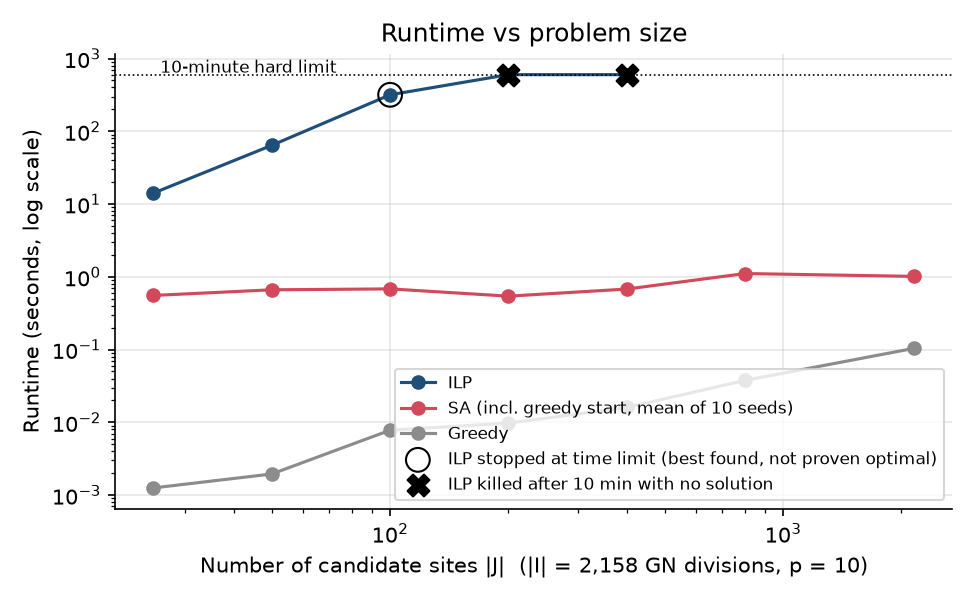

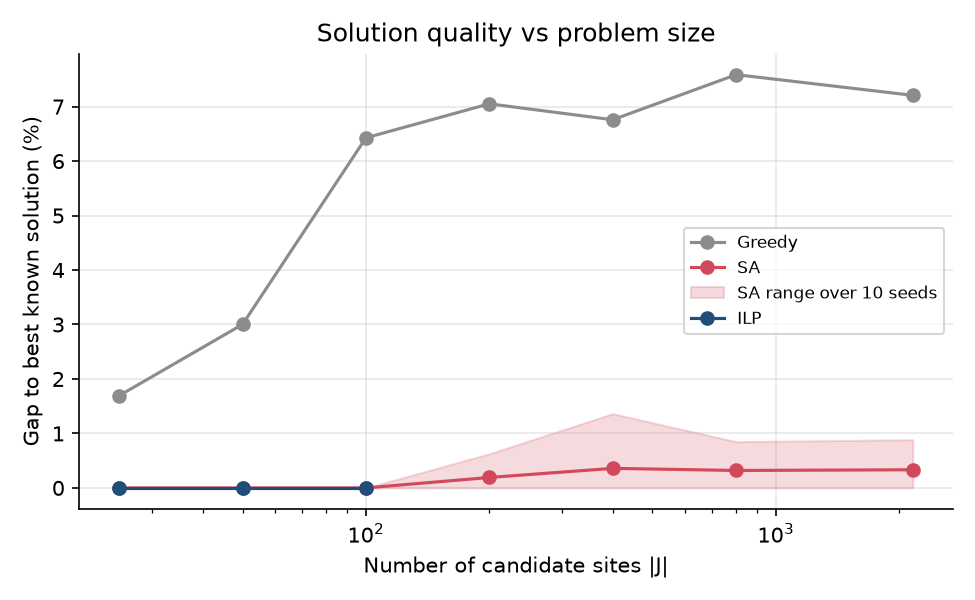

In [12]:
display(Image("figures/fig2_runtime_scalability.png"))
display(Image("figures/fig3_quality_gap.png"))

## 9. Experiment E3: policy trade-off: how many bases?

**Goal:** a decision-support question for the health authority: how does service improve as
we add more ambulance bases? Whole province, DS centres as candidates, p = 4, 6, 8, 10, 12, 15, 20.
The table shows the **optimal (ILP)** solution for each p.

In [13]:
e3 = pd.read_csv("results/e3_tradeoff.csv")
e3[e3.method == "ILP"][["p", "avg_time", "max_time", "cover_15", "cover_30", "runtime", "optimal"]]

,p,avg_time,max_time,cover_15,cover_30,runtime,optimal
6,4,34.435,110.306,0.131,0.377,70.369,True
13,6,27.863,110.306,0.212,0.584,54.650,True
20,8,23.859,110.306,0.260,0.696,41.565,True
27,10,21.325,110.306,0.315,0.804,33.076,True
34,12,19.633,90.820,0.342,0.866,20.894,True
41,15,17.579,90.820,0.398,0.923,53.073,True
48,20,15.113,90.820,0.544,0.951,13.495,True


**Key observations:** going from 4 to 10 bases cuts the average time from 34 to 21 min and raises
30-minute coverage from 38% to 80%. After about 10–12 bases each extra base helps less
(diminishing returns). `max_time` stays at 110 min until p = 12, because one remote area is badly served.

**Figure 4**: average response time (left axis) and % of population within 15 / 30 min
(right axis) vs number of bases, using the optimal ILP solutions.

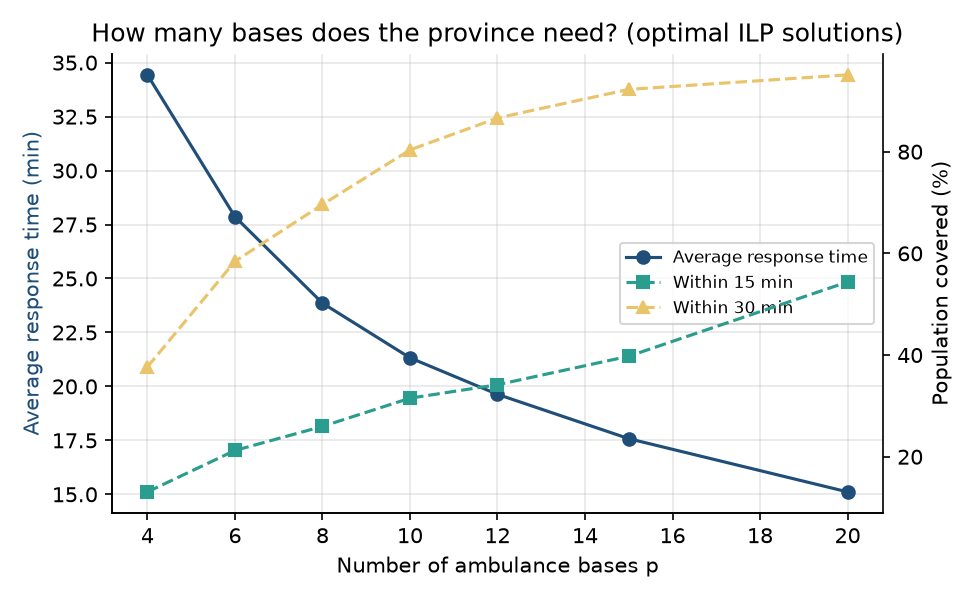

In [14]:
display(Image("figures/fig4_bases_tradeoff.png"))

## 10. Discussion and conclusion

### 10.1 Exact method vs heuristics as the problem grows (E1, E2)
* On the realistic 46-site case the ILP is fast and proves optimality; SA matches it.
* As the number of candidate sites grows, ILP time grows very fast: 14 s (25 sites), 64 s (50 sites), and no proven answer within 10 minutes from 100 sites up.
* SA always finished in about 1 second and stayed within about 1% of the best answer found.
* Greedy got worse as the problem grew (about 2% off at 25 sites, about 7% off at 200+ sites).
* For 200+ sites the gap is measured against the best answer found, not a proven optimum.
* More candidate sites can give better locations (20.93 min with 100 GN sites vs 21.33 min with 46 DS centres), but only the heuristic can handle the large cases.

### 10.2 How many ambulance bases are needed? (E3)
* More bases always lower the average time, but each extra base helps less:
  * 4 → 6 bases: saves about 6.6 min
  * 10 → 12 bases: saves about 1.7 min
  * 15 → 20 bases: saves about 2.5 min in total
* Share of people reached within 30 min: 38% (4 bases) → 80% (10 bases) → 95% (20 bases).
* Around 10–12 bases looks like a good balance between cost and service.
* The longest trip (about 110 min) does not improve until 12 bases, so one remote area needs special attention.

### 10.3 Average vs fairness
* The p-median model only lowers the *average* time, so remote areas can end up worse off.
* Example: in Puttalam the best-average plan has a longest trip of 110 min, while greedy's plan has 91 min.
* Other models focus on fairness, e.g. p-center (shortest worst-case time) or maximal covering (most people within a time limit).

### 10.4 Limitations
* Travel time is estimated from straight-line distance and a fixed speed (40 km/h), not real roads or traffic.
* Each GN division is treated as one point at its centre.
* Demand is based on 2012 population, not actual emergency calls.
* The model assumes an ambulance is always free (no busy ambulances, no queues).
* Candidate sites are area centres, not real hospitals or stations.

### 10.5 Conclusion
* Greedy + SA gives near-optimal plans in about 1 second, even for the full province.
* The ILP with its LP bound is the right tool for certifying answers on realistic-size problems.
* Recommended: about 10–12 bases for the North Western Province, plus a separate fix for the most remote area.